**CSCI 597: ASSIGNMENT - 02**

**Question 1.(a):**
<br><br>
A language model is a computer program that learns how words are commonly used together in a language.<br>By reading large amounts of text, it learns patterns between words and can predict which word might come next in a sentence. <br><br>
For example: if the sentence is "I drink milk every ___",the model might predict "morning",because it has seen similar patterns during training. <br>
<br>
The main goal of a language model is to understand context and generate meaningful text.And also to predict or generate text by using the words that come before it to determine the most likely next word.<br>

**Question 1.(b):**<br>
 - RNNs and LSTMs handle words one at a time,which can make them slow with long sentences.RNNs may also forget information from earlier parts of the text when the sequence becomes very long.<br>

 - LSTMs are designed to remember information for longer, but they may still miss important details in very long texts.<br>
 
 - Transformers take a different approach by looking at all the words in a sentence at once through self-attention.This allows them to find connections between words,even if they are far apart,so they work better with large amounts of text and long-range relationships.


**Question 1.(c):**<br>

- Greedy decoding chooses the word with the highest probability at each step and immediately moves to the next word. <br>
- This method is fast and simple,but it can miss better sentences because it only considers one choice at a time.<br>

- Beam search keeps multiple possible word sequences at each step and compares them before selecting the final output.<br>
- This often produces more natural and accurate sentences,but it requires more computation and takes longer to generate results.<br>

- Beam search is useful in tasks such as language translation,where finding the best overall sentence is more important than generating the fastest response.<br>
For example: when translating an English sentence into any south Indian languages like Kannada,Tamil or Telugu, beam search can compare multiple translation options and choose the sentence that sounds more natural and accurate.

**Question 1.(d):Zero-Shot Sentiment Analysis Using SmolLM-135M**<br>
<br>
In this exercise, I performed zero-shot sentiment analysis on two sets of movie reviews. The first set consisted of reviews created by me, while the second set was selected from the IMDb dataset. Using both sets helped me understand how the model performs on simple custom reviews as well as real-world movie reviews.




In [1]:
# Checking imports
from transformers import pipeline, set_seed
import pandas as pd

print("packages loaded successfully!")

packages loaded successfully!


Step-(1): Creating movie reviews
<br>
I created 3 movie reviews, where one review is positive,one is negative and one is neutral or mixed review.

In [16]:
my_reviews = [ 
    {"name": "review 1", 
     "text": "The movie was simply amazing,the acting of the main lead felt real and the ending made me smile.", 
     "expected": "Positive"},

    {"name": "review 2", 
     "text":"I did not enjoy this movie because the story was confusing and the characters felt flat", 
     "expected": "Negative"},        
              
    {"name": "review 3", 
     "text":"The film had some good scenes,but some parts were slow and not very exciting.", 
     "expected": "Neutral"}
    ]


Step-(2) and Step-(3): Loading and running SmolLM-135M Model ,<br>
I used SmolLM-135M, because it is one of the models suggested in the assignment instructions and it produced clearer sentiment predictions than GPT-2.

In [17]:
set_seed(10)
from transformers import pipeline

gen = pipeline(
    "text-generation",
    model="HuggingFaceTB/SmolLM-135M"
)

my_rows = []

for item in my_reviews:
    review_text = item["text"]

    my_prompt = f"""Movie review: "{review_text}"

Sentiment options: Positive, Negative, Neutral.
The best sentiment is"""

    ans = gen(
        my_prompt,
        max_new_tokens=15,
        do_sample=True,
        temperature=0.7,
        pad_token_id=50256
    )

    full_text = ans[0]["generated_text"]
    model_output = full_text.replace(my_prompt, "").strip()

    check_text = model_output.lower()

    if "positive" in check_text:
        pred = "Positive"
    elif "negative" in check_text:
        pred = "Negative"
    elif "neutral" in check_text:
        pred = "Neutral"
    else:
        pred = "Not clear"

    explanation = "The model output was checked for sentiment words such as positive, negative, or neutral."

    my_rows.append([item["name"], review_text, pred, model_output])

    print(item["name"])
    print("Review:", review_text)
    print("Model output:", check_text)
    print("Predicted Sentiment:", pred)
    print()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


review 1
Review: The movie was simply amazing,the acting of the main lead felt real and the ending made me smile.
Model output: positive because it was fun, entertaining, and memorable.

when you
Predicted Sentiment: Positive



[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


review 2
Review: I did not enjoy this movie because the story was confusing and the characters felt flat
Model output: "neutral". the most negative of all the options was "frustration
Predicted Sentiment: Negative

review 3
Review: The film had some good scenes,but some parts were slow and not very exciting.
Model output: always the positive one.

## 3. the best emotion
Predicted Sentiment: Positive



Step-(4):Presenting the results
<br>
The table below shows each review,the model's predicted sentiment,and a short explanation

In [18]:
import pandas as pd

pd.set_option("display.max_colwidth", None)

sentiment_df = pd.DataFrame(
    my_rows,
    columns=[
        "Movie Review",
        "Review Text",
        "Predicted Sentiment",
        "Model Explanation"
    ]
)

sentiment_df

,Movie Review,Review Text,Predicted Sentiment,Model Explanation
0,review 1,"The movie was simply amazing,the acting of the main lead felt real and the ending made me smile.",Positive,"positive because it was fun, entertaining, and memorable.\n\nWhen you"
1,review 2,I did not enjoy this movie because the story was confusing and the characters felt flat,Negative,"""neutral"". The most negative of all the options was ""frustration"
2,review 3,"The film had some good scenes,but some parts were slow and not very exciting.",Positive,always the positive one.\n\n## 3. The best emotion


Step-(5):Reflection:<br><br>
For this question, I wrote three movie reviews, one positive, one negative and one mixed. I used a zero-shot prompt with a language model SmolLM to classify them. The model got the positive and negative reviews right, but it labeled the mixed review as positive, missing the fact that it had both good and bad points.<br>

A big advantage of using a generative language model as a classifier is that it can do sentiment analysis without extra training data.Just giving it a prompt was enough for the model to understand the task and predict the sentiment.This makes zero-shot classification flexible and easy to use with different types of text.<br>

However, there were some linitations.Sometimes the model gave extra text instead of just a sentiment label. It also had trouble with the mixed review because it included both good and bad comments. The model seemed to pay more attention to the positive words and missed some of the negative parts. This shows that generative language models are not always accurate, especially when the sentiment is mixed or unclear.<br>

Overall,the zero-shot sentiment analysis can be helpful, but its predictions are not always reliable when reviews have mixed or neutral opinions.

**Question 1.(d): Zero-Shot Sentiment Analysis Using SmolLM**<br>

For this task, I used the IMDb dataset from Kaggle. I selected one positive, one negative, and one neutral review from the training file. Then I used the same zero-shot prompt for each review and recorded the model output in a table.

In [19]:
#Step-(1):Select the first 3 movie reviews from the IMDb dataset for sentiment analysis
import pandas as pd
from transformers import pipeline, set_seed

set_seed(10)

# Loading the IMDb train file from the same folder as the notebook
movie_data = pd.read_csv("train.tsv", sep="\t")

review_col = "review"
sentiment_col = "sentiment"

print("Dataset loaded successfully")
print(movie_data.columns.tolist())
print(movie_data[sentiment_col].value_counts())

Dataset loaded successfully
['sentiment', 'review']
sentiment
2    10932
0    10929
1    10884
Name: count, dtype: int64


In [20]:
# Select one review for each sentiment type
positive_text = movie_data[movie_data[sentiment_col] == 2][review_col].iloc[0][:400]
neutral_text = movie_data[movie_data[sentiment_col] == 1][review_col].iloc[0][:400]
negative_text = movie_data[movie_data[sentiment_col] == 0][review_col].iloc[0][:400]

my_reviews = [
    {"name": "Review 1", "text": positive_text, "actual": "Positive"},
    {"name": "Review 2", "text": negative_text, "actual": "Negative"},
    {"name": "Review 3", "text": neutral_text, "actual": "Neutral"}
]

In [21]:
#Step-(2):Loading the SmolLM model for zero-shot sentiment analysis
gen = pipeline(
    "text-generation",
    model="HuggingFaceTB/SmolLM-135M"
)

rows = []

#Step-(3):Creating the prompt and running the model for each movie review    
for r in my_reviews:

    prompt = f"""Movie review: "{r['text']}"

Sentiment options: Positive, Negative, Neutral.
The best sentiment is"""

    output = gen(
        prompt,
        max_new_tokens=15,
        do_sample=True,
        temperature=0.7,
        pad_token_id=50256
    )

    full_text = output[0]["generated_text"]
    model_output = full_text.replace(prompt, "").strip().split("\n")[0]

    check_text = model_output.lower()

    if "positive" in check_text:
        predicted = "Positive"
    elif "negative" in check_text:
        predicted = "Negative"
    elif "neutral" in check_text:
        predicted = "Neutral"
    else:
        predicted = "Not clear"

    rows.append([
        r["name"],
        r["actual"],
        r["text"][:400],     #only first 400 characters
        predicted,
        model_output
    ])


#Displaying the model prediction for each review
    print("=" * 80)
    print(r["name"])
    print()

    print("Actual Sentiment:", r["actual"])
    print()

    print("Review Text:")
    print(r["text"][:400])  
    print()

    print("Model Output:")
    print(model_output)
    print()

    print("Predicted Sentiment:", predicted)
    print("=" * 80)
    print()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Review 1

Actual Sentiment: Positive

Review Text:
Usually the debate is wether godfather or Goodfellas is a better mfia film. I think in terms of cinema and acting their on par, but if Goodfellas edges it for me because it is based on a true story and the characters are almost portrayed like the real life characters....especially Joe pesci what a performance, 10/10 deserved the Oscar that year!

Model Output:
Negative because it is the most negative film.

Predicted Sentiment: Negative



[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Review 2

Actual Sentiment: Negative

Review Text:
I can not believe that this movie received all the awards that it did. It was long, slow-moving, predictable, and the acting was terrible. I can't believe that they cut out over an hours worth of video to get it down to this length. I wish that Gandalf would have just given Frodo a giant eagle in the first movie so that he could just fly in and drop the ring in the volcano and save us the pain of 

Model Output:
"positive". The worst is "negative".

Predicted Sentiment: Positive

Review 3

Actual Sentiment: Neutral

Review Text:
But it's really slow to catch on . For me a movie is like a rocket. If it ain't fast enough , it wouldn't get anywhere.Despite Jim Carrey's excellent performance (an oblivious deviation to the Jim that I loved in Bruce Almighty and The Truman Show) and perhaps , the most innovative plot line of the decade ; it builds up very slowly.I might even say that it is boring to an extend.But there are many

Model Output

In [22]:
#Step-(4): Presenting the result in a table
pd.set_option("display.max_colwidth", None)

sentiment_table = pd.DataFrame(
    rows,
    columns=[
        "Movie Review",
        "Actual Sentiment",
        "Review Text",
        "Predicted Sentiment",
        "Model Explanation"
    ]
)

sentiment_table

,Movie Review,Actual Sentiment,Review Text,Predicted Sentiment,Model Explanation
0,Review 1,Positive,"Usually the debate is wether godfather or Goodfellas is a better mfia film. I think in terms of cinema and acting their on par, but if Goodfellas edges it for me because it is based on a true story and the characters are almost portrayed like the real life characters....especially Joe pesci what a performance, 10/10 deserved the Oscar that year!",Negative,Negative because it is the most negative film.
1,Review 2,Negative,"I can not believe that this movie received all the awards that it did. It was long, slow-moving, predictable, and the acting was terrible. I can't believe that they cut out over an hours worth of video to get it down to this length. I wish that Gandalf would have just given Frodo a giant eagle in the first movie so that he could just fly in and drop the ring in the volcano and save us the pain of",Positive,"""positive"". The worst is ""negative""."
2,Review 3,Neutral,"But it's really slow to catch on . For me a movie is like a rocket. If it ain't fast enough , it wouldn't get anywhere.Despite Jim Carrey's excellent performance (an oblivious deviation to the Jim that I loved in Bruce Almighty and The Truman Show) and perhaps , the most innovative plot line of the decade ; it builds up very slowly.I might even say that it is boring to an extend.But there are many",Positive,always the positive.


Step-(5):Reflection:<br><br>
For this,I picked three movie reviews from the IMDb dataset and used a generative language model (SmolLM) to do zero-shot sentiment analysis. The reviews I chose were positive, negative, and neutral. After running the model, I compared its predictions to the actual labels from the dataset<br>

The model did not perform as expected. It marked the positive review as negative, the negative review as positive, and also called the neutral review positive. This shows the model struggled to understand the main idea and tone of the reviews.<br>

One advantage of using a generative language model is that it can handle classification tasks without needing extra training data. This makes zero-shot analysis flexible and easy to use. However, the model might focus too much on certain words or phrases instead of the overall meaning of the review, which can lead to mistakes. <br>

Overall,Zero-shot sentiment analysis is possible, but how well it works depends on the quality of the model and the prompt.<br>

**Question 2.(a):**<br>
An autoencoder is a type of neural network that learns to shrink data into a simpler form and then rebuild it to look like the original. People often use autoencoders for feature extraction, reducing data size, and working with images.<br>

The encoder is the first part of the network. It takes the input and turns it into a smaller set of important features. These features are kept in what is called the latent space.<br>

The latent space is a compressed version of the input. It keeps the most important information about the original data and leaves out extra details. Since it uses fewer values than the original, it is called a compressed representation.<br>

The decoder is the last part of the network. It takes the compressed data from the latent space and tries to rebuild the original input as closely as it can.<br>

**Question 2.(b):** <br>
A standard autoencoder takes an input, maps it to a single point in the latent space, and then tries to rebuild the original data from that point.Its main goal is to reduce reconstruction error.<br>

A Variational Autoencoder (VAE) works in a different way.Rather than mapping an input to just one point, it maps the input to a probability distribution defined by a mean and variance. During training, the model samples from this distribution to reconstruct the input.<br>

Using a probability distribution helps organize the latent space so that similar inputs end up near each other. This makes it possible for the VAE to create new data samples by picking points from the latent space.For this reason, VAEs are often used for image generation and data synthesis.



**Question 2.(c):**<br>
CLIP (Contrastive Language-Image Pre-training) is a model that learns relationship between images and text. It learns by looking at lots of image and text pairs during training and figuring out which descriptions go with which images.<br>

CLIP converts both images and text into numbers called embeddings.When an image and its description match, their embeddings are brought closer together. If they do not match, the embeddings are moved further apart.<br>

Since CLIP learns general visual concepts about images and language, it can do zero-shot image classification. This means it can look at a new image, compare it to different text labels, and pick the label that matches best, all without extra training.



**Question 2.(d): Zero-Shot image classification using CLIP** <br>
In this exercise, I used the CLIP model from Hugging Face to classify images without providing any additional training examples.

For this task,I am importing required libraries to load images, process text labels, and run the CLIP model. 


In [23]:
import torch
import requests
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

print("Libraries loaded successfully")

Libraries loaded successfully



I selected "openai/clip-vit-base-patch32" because it is smaller and easier to run on my laptop.

In [24]:
model_name = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(model_name)
clip_processor = CLIPProcessor.from_pretrained(model_name)

print("CLIP model loaded successfully")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded successfully


Step-(1): Select Images <br>
I selected three images with different objects: a coffee mug, a car, and running shoes. I saved these images in the same folder as my notebook and used them as inputs for the CLIP zero-shot image classification exercise.

In [25]:
# Step-(1): Loading selected local images for CLIP classification
image_files = [
    ("Coffee Mug", "coffee.jpeg"),
    ("Car", "car.jpeg"),
    ("Running Shoes", "shoes.jpeg")
]

images = []

for image_name, file_name in image_files:
    img = Image.open(file_name).convert("RGB")
    images.append((image_name, img))

print("Total images loaded:", len(images))

Total images loaded: 3


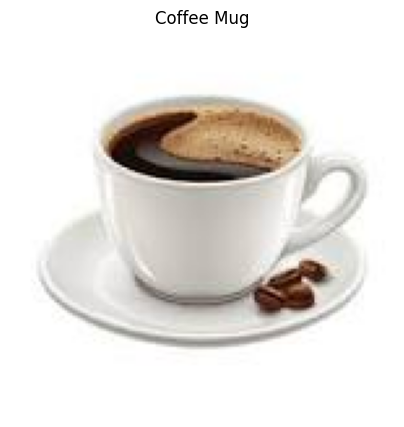

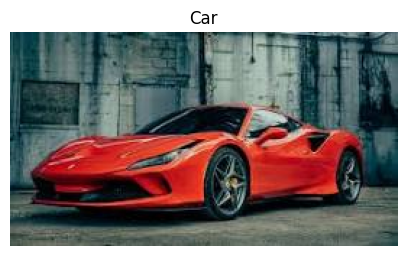

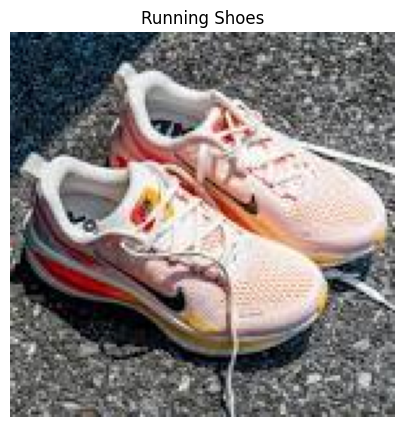

In [26]:
import matplotlib.pyplot as plt

for image_name, img in images:

    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(image_name)

    plt.show()

Step-(2):I created five candidate labels. CLIP will compare each image with these labels and select the closest match.

In [27]:
candidate_labels = [
    "a photo of a ceramic coffee mug",
    "a photo of a car on the road",
    "a photo of an apartment building",
    "a photo of running shoes",
    "a photo of a public library"
]

candidate_labels

['a photo of a ceramic coffee mug',
 'a photo of a car on the road',
 'a photo of an apartment building',
 'a photo of running shoes',
 'a photo of a public library']

Step-(3): CLIP compares each image with the candidate text labels and returns the label with the highest similarity score.

In [28]:
result_rows = []

for image_name, img in images:

    inputs = clip_processor(
        text=candidate_labels,
        images=img,
        return_tensors="pt",
        padding=True
    )

    with torch.no_grad():
        outputs = clip_model(**inputs)

    similarity_scores = outputs.logits_per_image
    probabilities = similarity_scores.softmax(dim=1)

    best_index = probabilities[0].argmax().item()
    predicted_label = candidate_labels[best_index]
    confidence_score = probabilities[0][best_index].item()

    result_rows.append([
        image_name,
        ", ".join(candidate_labels),
        predicted_label,
        round(confidence_score, 4)
    ])

    print("Image:", image_name)
    print("Predicted Label:", predicted_label)
    print("Confidence Score:", round(confidence_score, 4))
    print()

Image: Coffee Mug
Predicted Label: a photo of a ceramic coffee mug
Confidence Score: 0.9994

Image: Car
Predicted Label: a photo of a car on the road
Confidence Score: 0.975

Image: Running Shoes
Predicted Label: a photo of running shoes
Confidence Score: 1.0



Step-(4):The table below shows each image, the candidate labels, the predicted label, and the confidence score.

In [29]:
clip_results = pd.DataFrame(
    result_rows,
    columns=[
        "Images",
        "Candidate Labels",
        "Predicted Label",
        "Confidence Score"
    ]
)

clip_results

,Images,Candidate Labels,Predicted Label,Confidence Score
0,Coffee Mug,"a photo of a ceramic coffee mug, a photo of a car on the road, a photo of an apartment building, a photo of running shoes, a photo of a public library",a photo of a ceramic coffee mug,0.9994
1,Car,"a photo of a ceramic coffee mug, a photo of a car on the road, a photo of an apartment building, a photo of running shoes, a photo of a public library",a photo of a car on the road,0.9750
2,Running Shoes,"a photo of a ceramic coffee mug, a photo of a car on the road, a photo of an apartment building, a photo of running shoes, a photo of a public library",a photo of running shoes,1.0000


Step-(5):Reflection <br>

Zero-shot image classification lets a model predict what category an image belongs to,even if it has not seen examples from that category before.The model relies on what it already knows to compare the image with a list of text labels and pick the best match.<br>

CLIP does not need extra training for new categories because it has already learned how images and text relate by studying a huge set of image-text pairs. This helps the model understand visual concepts and match them with natural language descriptions.<br>

In this program, the model performed very well.It correctly identified the coffee mug as a ceramic coffee mug with a confidence score of 0.9994. The car was identified as a car on the road with a score of 0.9750. The running shoes were also classified correctly with a perfect score of 1.0000. These results show the model was very confident in its predictions.<br>

Many things can affect how well CLIP works, such as image quality, lighting, how visible the object is, background clutter, and which labels are chosen. Using more specific and meaningful labels usually helps the model give better results. Overall, this program showed that CLIP is effective for zero-shot image classification.<br>